<a href="https://colab.research.google.com/github/Claudioigles/Dataa-Analytics-con-Python/blob/main/Proyecto_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# ==============================================================================
# 1. PREPARACIÓN INICIAL: CARGA Y ADAPTACIÓN DE DATASETS
# ==============================================================================
df_ventas = pd.read_csv('ventas.csv')
# Homogeneizamos los encabezados pasándolos a minúsculas para prevenir conflictos
df_ventas.columns = df_ventas.columns.str.lower()

# Reajuste de nombres para asegurar compatibilidad de columnas
column_mapping = {
    'fecha': 'fecha_venta',
    'id_producto': 'producto',
    'id_venta': 'id_venta'
}
for col_actual, col_destino in column_mapping.items():
    if col_actual in df_ventas.columns and col_destino not in df_ventas.columns:
        df_ventas[col_destino] = df_ventas[col_actual]

# En caso de no contar con precio, establecemos un valor de contingencia
if 'precio' not in df_ventas.columns:
    print("Aviso: Columna 'precio' ausente. Aplicando precio estandarizado temporal.")
    df_ventas['precio'] = '100'

print("1. Datos importados y estructurados. Dimensión alcanzada:", df_ventas.shape)


# ==============================================================================
# 2. CÁLCULO DE MÉTRICAS CLAVE: INGRESOS POR PERIODO MENSUAL
# ==============================================================================
df_aux = df_ventas.dropna(subset=['precio', 'cantidad']).copy()

var_precio = pd.to_numeric(df_aux['precio'].astype(str).str.replace(r'[^\d.]', '', regex=True), errors='coerce').fillna(0)
var_cantidad = pd.to_numeric(df_aux['cantidad'], errors='coerce').fillna(0)
var_mes = pd.to_datetime(df_aux['fecha_venta'], errors='coerce').dt.to_period('M')

# Obtención de ingresos totales por fila
var_ingresos = var_precio * var_cantidad

ventas_mensuales = var_ingresos.groupby(var_mes).sum().reset_index()
ventas_mensuales.columns = ['mes', 'total_ventas']

print("\n2. Facturación agrupada por mes mediante operadores vectoriales:")
print(ventas_mensuales)


# ==============================================================================
# 3. ORGANIZACIÓN INTERNA: CREACIÓN DE ESTRUCTURAS DE DATOS
# ==============================================================================
# Agrupamos los registros seleccionados en un diccionario para generar una muestra estructurada
datos_ventas_dict = {
    'producto': df_aux['producto'].head(5).tolist() if 'producto' in df_aux.columns else [f"Prod_{i}" for i in range(5)],
    'precio': var_precio.head(5).tolist(),
    'cantidad': var_cantidad.head(5).astype(int).tolist()
}

df_estructura = pd.DataFrame(datos_ventas_dict)
df_estructura['subtotal'] = df_estructura['precio'] * df_estructura['cantidad']

print("\n3. Conversión de estructuras nativas (diccionario) a formato tabular:")
print(df_estructura)


# ==============================================================================
# 4. EXPLORACIÓN PRELIMINAR: PRIMER ACERCAMIENTO A LOS DATAFRAMES
# ==============================================================================
print("\n4. Resultados del diagnóstico preliminar de variables:")
print("--- Resumen estructural y tipos detectados ---")
print(df_ventas.info())
print("\n--- Primeros registros de muestra ---")
print(df_ventas.head())
print("\n--- Métricas cuantitativas generales ---")
print(df_ventas.describe())
print("\n--- Métricas cualitativas y categóricas ---")
print(df_ventas.describe(include='object'))


# ==============================================================================
# 5. CONTROL DE CALIDAD: REVISIÓN DE REGISTROS NULOS Y REPETIDOS
# ==============================================================================
nulos_por_columna = df_ventas.isnull().sum()
filas_nulas = df_ventas[df_ventas.isnull().any(axis=1)]
cantidad_duplicados = df_ventas.duplicated().sum()

print("\n5. Reporte inicial de inconsistencias:")
print("Casillas vacías por cada columna:\n", nulos_por_columna)
print("\nFilas que contienen registros incompletos:\n", filas_nulas)
print(f"\nRegistros duplicados detectados en el set: {cantidad_duplicados}")


# ==============================================================================
# 6 (1). DEPURACIÓN INTEGRAL DE LOS CAMPOS DEL DATASET
# ==============================================================================
df_limpio = df_ventas.copy()

# Inicialización de columnas requeridas para evitar interrupciones de flujo
columnas_esperadas = ['producto', 'categoria', 'fecha_venta']
for col in columnas_esperadas:
    if col not in df_limpio.columns:
        df_limpio[col] = "No Especificado" if col != 'fecha_venta' else pd.Timestamp('2024-01-01')

# Exclusión de redundancias y registros repetidos por transacción
df_limpio = df_limpio.drop_duplicates()
if 'id_venta' in df_limpio.columns:
    df_limpio = df_limpio.drop_duplicates(subset=['id_venta'])

# Formateo y limpieza de cadenas de texto
for col in columnas_esperadas:
    df_limpio[col] = df_limpio[col].astype(str).str.strip()
    df_limpio[col] = df_limpio[col].replace({'': pd.NA, 'nan': pd.NA, 'NaN': pd.NA, 'None': pd.NA, 'null': pd.NA})

# Conversión y saneamiento de caracteres numéricos monetarios
df_limpio['precio'] = pd.to_numeric(
    df_limpio['precio'].astype(str).str.replace(r'[^\d.]', '', regex=True),
    errors='coerce'
)
df_limpio['cantidad'] = pd.to_numeric(df_limpio['cantidad'], errors='coerce')
if 'id_venta' in df_limpio.columns:
    df_limpio['id_venta'] = pd.to_numeric(df_limpio['id_venta'], errors='coerce')
else:
    df_limpio['id_venta'] = range(1, len(df_limpio) + 1)

# Normalización del formato cronológico
df_limpio['fecha_venta'] = pd.to_datetime(df_limpio['fecha_venta'], errors='coerce')

# Filtrado final para retener únicamente registros completamente íntegros
df_limpio = df_limpio.dropna().copy()

# Configuración final de tipologías y cálculo de montos globales
df_limpio['id_venta'] = df_limpio['id_venta'].astype(int)
df_limpio['cantidad'] = df_limpio['cantidad'].astype(int)
df_limpio['ingresos'] = (df_limpio['precio'] * df_limpio['cantidad']).round(2)

print("\n6. Resultados tras el proceso completo de depuración:")
print(f"Filas iniciales: {len(df_ventas)} -> Filas limpias resultantes: {len(df_limpio)}")
print(f"Registros repetidos remanentes: {df_limpio.duplicated().sum()}")
print(f"Nulos restantes:\n{df_limpio.isnull().sum()}")
print("\n--- Extracto del set de datos final de ventas depuradas ---")
print(df_limpio.head())


# ==============================================================================
# 7 (2). FILTRADO Y PROCESAMIENTO: ARTÍCULOS CON MAYOR FACTURACIÓN
# ==============================================================================
df_productos = df_limpio.groupby(['producto', 'categoria'], as_index=False).agg(
    ingresos_totales=('ingresos', 'sum'),
    unidades_vendidas=('cantidad', 'sum'),
    precio_promedio=('precio', 'mean'),
    operaciones=('id_venta', 'count')
)

umbral_p75 = df_productos['ingresos_totales'].quantile(0.75)
df_alto_rendimiento = (
    df_productos[df_productos['ingresos_totales'] >= umbral_p75]
    .sort_values(by='ingresos_totales', ascending=False)
    .reset_index(drop=True)
)

print(f"\n7. Catálogo de artículos líderes en desempeño (Ventas >= ${umbral_p75:,.2f}):")
print(df_alto_rendimiento)


# ==============================================================================
# 8 (3). SÍNTESIS DE DATOS: VOLUMEN DE VENTAS POR SEGMENTO O CATEGORÍA
# ==============================================================================
df_categorias = df_limpio.groupby('categoria', as_index=False).agg(
    ingresos_totales=('ingresos', 'sum'),
    unidades_vendidas=('cantidad', 'sum'),
    ticket_promedio=('ingresos', 'mean'),
    cantidad_ventas=('id_venta', 'count')
).sort_values(by='ingresos_totales', ascending=False)

df_categorias['porcentaje_ingresos'] = (
    (df_categorias['ingresos_totales'] / df_categorias['ingresos_totales'].sum()) * 100
).round(2)

print("\n8. Comportamiento comercial distribuido por categoría de producto:")
print(df_categorias)


# ==============================================================================
# 9 (4). CONSOLIDACIÓN INTERDISCIPLINARIA: CRUCE DE COMERCIAL Y MARKETING
# ==============================================================================
try:
    df_marketing = pd.read_csv('marketing.csv')
    df_marketing = df_marketing.drop_duplicates().dropna()
    if 'producto' in df_marketing.columns:
        df_marketing['producto'] = df_marketing['producto'].astype(str).str.strip()

    df_integrado = pd.merge(
        df_productos,
        df_marketing,
        on='producto',
        how='left'
    )
    print("\n9. Vinculación de métricas de ventas y campañas publicitarias completada:")
    print(df_integrado.head(10))
except FileNotFoundError:
    print("\n9. Nota: Es necesario que cargues el archivo 'marketing.csv' para efectuar la unión correspondiente.")

Aviso: Columna 'precio' ausente. Aplicando precio estandarizado temporal.
1. Datos importados y estructurados. Dimensión alcanzada: (3029, 10)

2. Facturación agrupada por mes mediante operadores vectoriales:
        mes  total_ventas
0   2024-01          2800
1   2024-02         83600
2   2024-03        102200
3   2024-04         89700
4   2024-05         95600
5   2024-06        108700
6   2024-07        101300
7   2024-08         92300
8   2024-09         91600
9   2024-10        100100
10  2024-11         93600
11  2024-12         91200

3. Conversión de estructuras nativas (diccionario) a formato tabular:
   producto  precio  cantidad  subtotal
0        25     100         5       500
1         5     100         1       100
2        25     100         3       300
3        15     100         5       500
4         2     100         5       500

4. Resultados del diagnóstico preliminar de variables:
--- Resumen estructural y tipos detectados ---
<class 'pandas.core.frame.DataFrame'>
R

/tmp/ipykernel_1531/2975700537.py:35: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  var_mes = pd.to_datetime(df_aux['fecha_venta'], errors='coerce').dt.to_period('M')
/tmp/ipykernel_1531/2975700537.py:124: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_limpio['fecha_venta'] = pd.to_datetime(df_limpio['fecha_venta'], errors='coerce')


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



cols = ['precio','cantidad','ingresos']

df_estadistico = df_limpio[cols].agg(['mean','median','min','max','var',"std"]).T

df_estadistico['moda'] = df_limpio[cols].mode().iloc[0]
df_estadistico['rango'] = df_estadistico['max'] - df_estadistico['min']
df_estadistico['RIC - (IQR)'] = df_limpio[cols].quantile(0.75) - df_limpio[cols].quantile(0.25)


print(df_estadistico.round(2))


            mean  median    min    max       var     std  moda  rango  \
precio    100.00   100.0  100.0  100.0      0.00    0.00   100    0.0   
cantidad    3.48     3.0    1.0    6.0      2.91    1.71     2    5.0   
ingresos  348.03   300.0  100.0  600.0  29079.16  170.53   200  500.0   

          RIC - (IQR)  
precio            0.0  
cantidad          3.0  
ingresos        300.0  


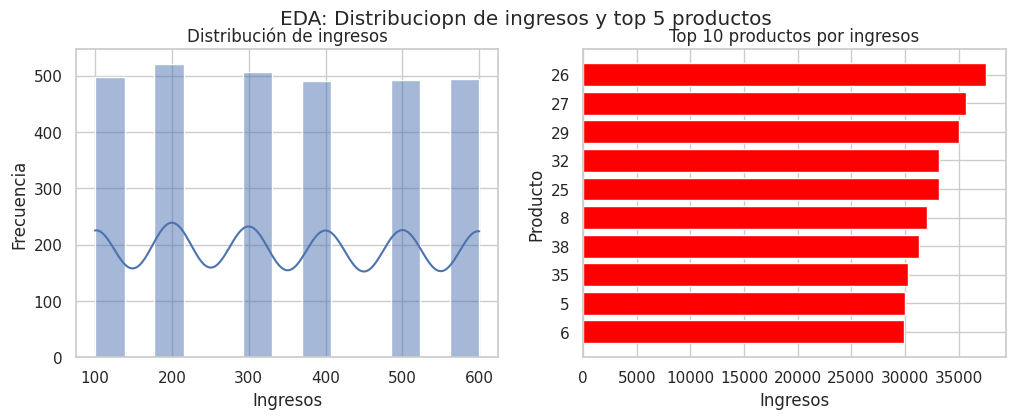

In [ ]:
fig_eda , axes = plt.subplots(1, 2, figsize=(12, 4))
fig_eda.suptitle('EDA: Distribuciopn de ingresos y top 5 productos')


sns.histplot(df_limpio['ingresos'], kde=True, ax=axes[0])


axes[0].set_title('Distribución de ingresos')
axes[0].set_xlabel('Ingresos')
axes[0].set_ylabel('Frecuencia')

top10_eda = df_productos.sort_values(by='ingresos_totales',ascending=True).tail(10)
axes[1].barh(top10_eda['producto'], top10_eda['ingresos_totales'],color="red")
axes[1].set_title('Top 10 productos por ingresos')
axes[1].set_xlabel('Ingresos')
axes[1].set_ylabel('Producto')



plt.show()

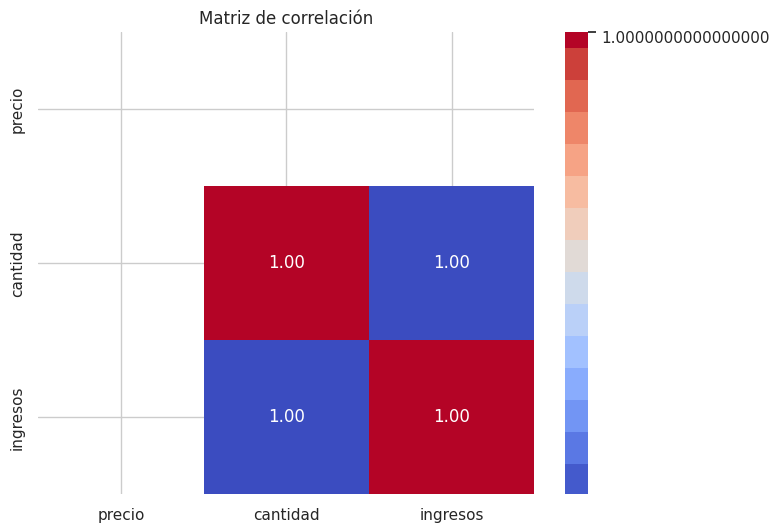

In [ ]:


matriz_corr = df_limpio[['precio','cantidad','ingresos']].corr()


plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de correlación')
plt.show()




4- Consolidación de datos: Consolidar todos los análisis previos y preparar un conjunto de datos final que resuma los hallazgos clave para la presentación.

In [ ]:
try:
    # Consolidamos los datos de ventas limpias (df_limpio) con los de marketing usando la columna común 'producto'
    df_consolidado = pd.merge(df_limpio, df_marketing, on='producto', how='left')

    # Guardamos el conjunto de datos consolidado final
    df_consolidado.to_csv('df_consolidado.csv', index=False)

    print("Consolidación exitosa. Primeras 5 filas del conjunto de datos consolidado:")
    print(df_consolidado.head(5))
except NameError as e:
    print(f"Error: Asegúrate de haber ejecutado las celdas anteriores. Detalle: {e}")
except Exception as e:
    print(f"Ocurrió un error al realizar la consolidación: {e}")

Consolidación exitosa. Primeras 5 filas del conjunto de datos consolidado:
   id_venta       fecha  id_cliente  id_producto  cantidad  método_pago  \
0       919  31/01/2024          10           25         5            1   
1       947  31/01/2024         106            5         1            4   
2      1317   31/1/2024         235           25         3            3   
3      1607   31/1/2024         114           15         5            1   
4      2038   31/1/2024         132            2         5            4   

     estado fecha_venta producto  precio        categoria  ingresos  \
0  Completa  2024-01-31       25     100  No Especificado       500   
1  Completa  2024-01-31        5     100  No Especificado       100   
2  Completa  2024-01-31       25     100  No Especificado       300   
3  Completa  2024-01-31       15     100  No Especificado       500   
4  Completa  2024-01-31        2     100  No Especificado       500   

   id_campanha canal  costo fecha_inicio fecha_

In [ ]:
# 2024-11-12

df_limpio['mes'] = df_limpio['fecha_venta'].dt.to_period('M') # 2024-11
df_limpio['trimestal'] = df_limpio['fecha_venta'].dt.to_period('Q') # 2024-Q4







<Axes: xlabel='categoria', ylabel='ingresos'>

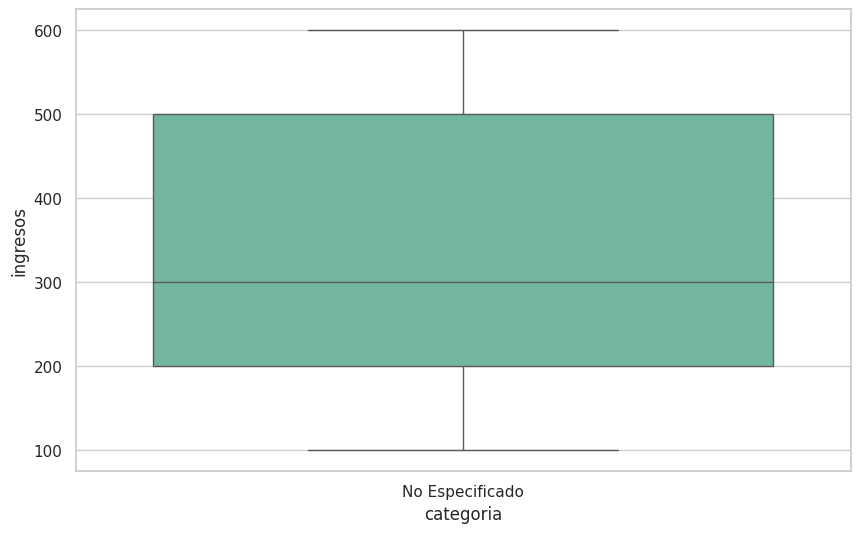

In [ ]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_limpio,
    x='categoria',
    y='ingresos',
    hue='categoria',
    palette='Set2' #viridis
)

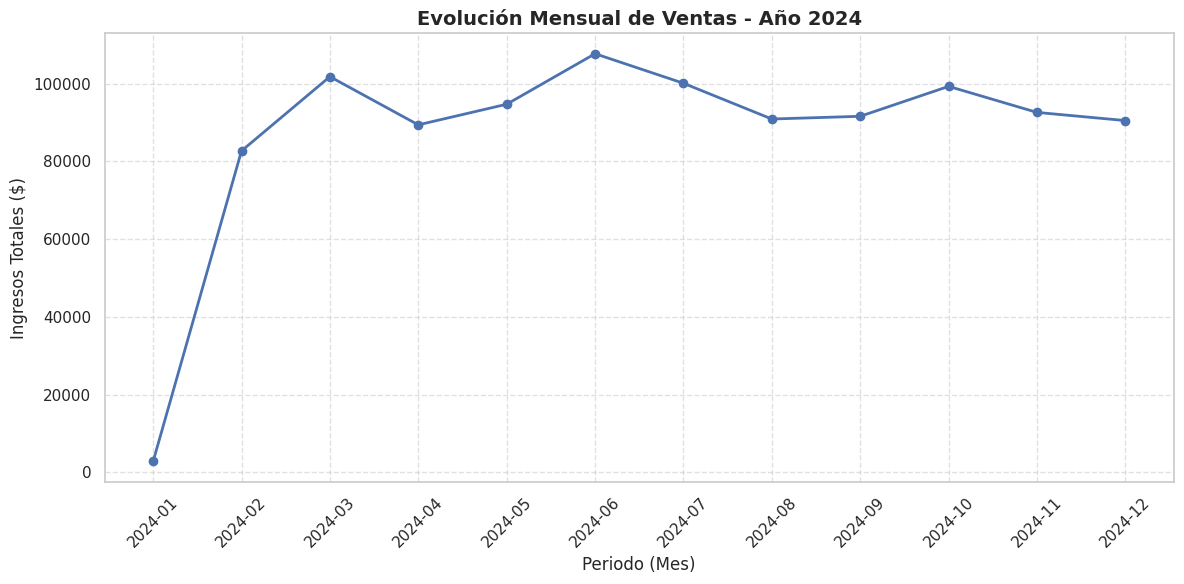

In [ ]:
# Agrupamos los ingresos por mes para ver la evolución de las ventas
ventas_mensuales_evolucion = df_limpio.groupby('mes')['ingresos'].sum().reset_index()
# Convertimos el periodo a string para una correcta visualización en el gráfico
ventas_mensuales_evolucion['mes'] = ventas_mensuales_evolucion['mes'].astype(str)

# Creamos el gráfico de líneas utilizando Matplotlib
plt.figure(figsize=(12, 6))
plt.plot(
    ventas_mensuales_evolucion['mes'],
    ventas_mensuales_evolucion['ingresos'],
    marker='o',
    color='b',
    linestyle='-',
    linewidth=2
)

# Añadimos títulos y etiquetas para mejorar la presentación
plt.title('Evolución Mensual de Ventas - Año 2024', fontsize=14, fontweight='bold')
plt.xlabel('Periodo (Mes)', fontsize=12)
plt.ylabel('Ingresos Totales ($)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)

# Mostramos el gráfico final
plt.tight_layout()
plt.show()